In [1]:
# python
import os
import sys
import importlib
# columnar analysis
from coffea import processor
from coffea.nanoevents import NanoAODSchema
import awkward as ak
from dask.distributed import Client, performance_report
# local
sidm_path = str(os.getcwd()).split("/sidm")[0]
if sidm_path not in sys.path: sys.path.insert(1, sidm_path)
from sidm.tools import utilities, sidm_processor, scaleout, llpnanoaodschema
# always reload local modules to pick up changes during development
importlib.reload(utilities)
importlib.reload(sidm_processor)
importlib.reload(scaleout)
# plotting
import matplotlib.pyplot as plt
utilities.set_plot_style()
%matplotlib inline
from hist import intervals
import coffea.util
# import numpy as np
import mplhep as hep
import numpy as np
import warnings

In [2]:
import yaml
yaml_file_path = '../../configs/ntuples/signal_2mu2e_v10.yaml'
# Open and read the YAML file
with open(yaml_file_path, 'r') as file:
    data = yaml.safe_load(file)
signals_all = list(data["llpNanoAOD_v2"]["samples"].keys())
# for x in range(len(signals_all)):
#     # if x == 0:
#     print("'" + signals_all[x] + "',")


In [3]:

DY = [ 
    "DYJetsToMuMu_M10to50",
    "DYJetsToMuMu_M50",
     
]



data = [ 
    "DoubleMuon_2018C",
 
]





DYJetsToMuMu_M10to50
[ 0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.          0.          0.         45.85460224 45.85460224 91.70920448
  0.         91.70920448 45.85460224  0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.        ]
ratio multiplied
[0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.00865575 0.00865575 0.0173115
 0.         0.0173115  0.00865575 0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.        ]
DYJetsToMuMu_M50
[       0.                0.                0.                0.
        0.                0.                0.                0.
        0.                0. 

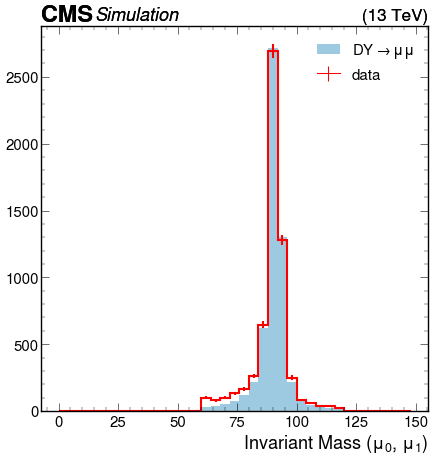

In [21]:
def sum_bgs_hist(bgs_list, histogram_name, channel_name, dir_name, ratio):
    """
    Sum histograms for a list of backgrounds.
    """
    summed_hist = None
    
    for x in bgs_list:
        print(x)
        output_bg = coffea.util.load(f"{dir_name}/output_{x}.coffea")
        
        hist = output_bg["out"][x]["hists"][histogram_name][channel_name, ::4j]
        print (hist.values())
        hist = ratio*hist
        print("ratio multiplied")
        print(hist.values())
        
        if summed_hist is None:
            summed_hist = hist.copy()
        else:
            summed_hist += hist
    # print(summed_hist.values())
    return summed_hist
channel_name = "Z_to_mumu_control_region"
hist_collections = "data_base"
dir_name = channel_name+hist_collections
dir_name_data = channel_name+"data_base"
output_data = coffea.util.load(f"{dir_name_data}/output_data.coffea" )
# print(output_signal["out"]["DoubleMuon_2018C"]["hists"].keys())

histogram_list  = [ 
 "muon_muon_invmass"

]


ratio  = 0.00018876508487265589
# sum_bg = sum_bgs_hist(QCD, histogram_name,channel_name )
for i, histogram_name in enumerate(histogram_list):
    # print(i, histogram_name, title_list[i])
    # plt.figure(figsize=(15, 12))
    # sum_bg_qcd = sum_bgs_hist(QCD, histogram_name,channel_name, dir_name )
    # sum_bg_tt = sum_bgs_hist(TT, histogram_name,channel_name, dir_name )
    sum_bg_dy = sum_bgs_hist(DY, histogram_name,channel_name, dir_name, ratio )
    
    utilities.plot(
    [
     #    sum_bg_qcd, 
     # sum_bg_tt,
      sum_bg_dy
    ],
    flow="none",
    yerr=True,
    density=False,
    histtype="fill",
    color=[
        # "#A9A9A9",
        #    "#FFB6C1",
           "#9ECAE1"
          ],
    label=[
        # "QCD", 
        #    "TT",
         r"DY$\rightarrow\mu\mu$"
          ],
    stack=True,
)
    labels = ["3cm", "150cm", "3cm", "150cm"]
    colors = ['r', 'g', 'b', 'purple']
    for i, s in enumerate(data):
        print(s)
        # parts = s.split("_")
        # mass = parts[1]
        # zd_mass = parts[2].replace("p", ".")
        # ctau = parts[3].replace("p", ".").replace("mm", "")
        # label =  zd_mass + ", " + labels[i]
        histogram = output_data["out"][s]["hists"][histogram_name][channel_name, ::4j]
        
        print(histogram.values())
        utilities.plot(histogram, flow ="none", yerr=True, density=False, label="data", color=colors[i], linewidth=3)
    # hep.label.exp_text(text="500 GeV ", loc=3) 
    # plt.yscale("log")
    # plt.title(histogram_name)
    plt.legend()
    # plt.ylim(1e-3, 1e0)
    plt.savefig("/home/cms-jovyan/SIDM/plots/" + histogram_name + ".png", dpi=300)
    plt.show()
    # plt.savefig("/home/cms-jovyan/SIDM/plots/" + histogram_name + ".png")
    plt.close()